Identificar o desempenho da regra ingênua

Importação de bibliotecas

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Configuração para os gráficos ficarem mais bonitos
sns.set_theme(style="whitegrid")

# Configuração dos caminhos (voltando uma pasta a partir de 'notebooks/')
ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"

ARQUIVO_TREINO = DATA_DIR / "5_split" / "oncological_panel_treino.csv"
ARQUIVO_TESTE = DATA_DIR / "5_split" / "oncological_panel_teste.csv"

print(f"Buscando dados em:\nTreino: {ARQUIVO_TREINO}\nTeste: {ARQUIVO_TESTE}")

Buscando dados em:
Treino: /home/maicongomes/Downloads/datasus-oncology-br/data/5_split/oncological_panel_treino.csv
Teste: /home/maicongomes/Downloads/datasus-oncology-br/data/5_split/oncological_panel_teste.csv


Carregamento dos dados

In [2]:
# Carregando as bases geradas pelo 05_split.py
df_treino = pd.read_csv(ARQUIVO_TREINO, low_memory=False)
df_teste = pd.read_csv(ARQUIVO_TESTE, low_memory=False)

print(f"Tamanho do Treino: {df_treino.shape}")
print(f"Tamanho do Teste: {df_teste.shape}")

# Espiando as primeiras linhas do treino
display(df_treino.head(3))

Tamanho do Treino: (408762, 36)
Tamanho do Teste: (175184, 36)


,ANO_DIAGN,ANOMES_DIA,ANO_TRATAM,ANOMES_TRA,UF_RESID,MUN_RESID,UF_TRATAM,MUN_TRATAM,UF_DIAGN,MUN_DIAG,...,latitude,longitude,capital,codigo_uf,siafi_id,ddd,fuso_horario,codigo_ibge_6,FAIXA_ETARIA,MES_DIAG
0,2024,2024-04-01,2024.0,202405.0,35,355030,35.0,355030.0,35,355030,...,-23.5329,-46.6395,1,35,7107,11,America/Sao_Paulo,355030,51-60,1
1,2017,2017-03-01,2017.0,201702.0,31,313170,31.0,310620.0,31,310620,...,-19.6239,-43.2312,0,31,4633,31,America/Sao_Paulo,313170,71-80,10
2,2020,2020-08-01,2020.0,202009.0,41,410940,41.0,410400.0,41,410400,...,-25.3902,-51.4623,0,41,7583,42,America/Sao_Paulo,410940,80+,8


Separação do alvo e distribuição

Distribuição da Variável Alvo no Treino (%):
ATRASO_60_DIAS
0    56.667939
1    43.332061
Name: proportion, dtype: float64


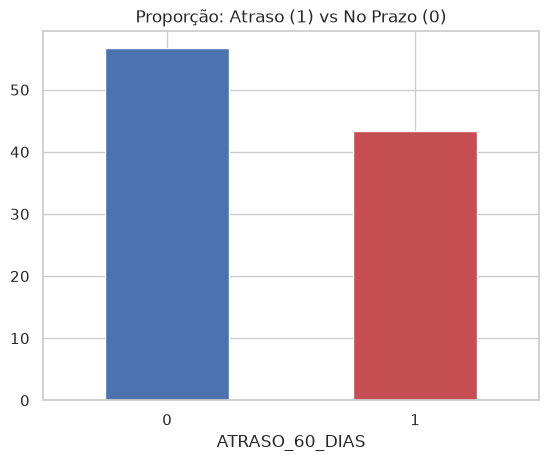

In [3]:
target = 'ATRASO_60_DIAS'

# Separando as variáveis preditivas (X) e a variável alvo (y)
X_treino = df_treino.drop(columns=[target])
y_treino = df_treino[target]

X_teste = df_teste.drop(columns=[target])
y_teste = df_teste[target]

# Verificando o desbalanceamento da base
distribuicao = y_treino.value_counts(normalize=True) * 100
print("Distribuição da Variável Alvo no Treino (%):")
print(distribuicao)

# Gráfico simples da distribuição
distribuicao.plot(kind='bar', color=['#4C72B0', '#C44E52'], title="Proporção: Atraso (1) vs No Prazo (0)")
plt.xticks(rotation=0)
plt.show()

Treinamento da linha de base

In [4]:
print("Treinando modelo Baseline (Estratégia: prever sempre a classe majoritária)...")

# Instanciando o DummyClassifier (Ele vai "aprender" a chutar sempre o que tem mais)
baseline_model = DummyClassifier(strategy='most_frequent')

# Treinando (ajustando) o modelo com os dados de treino
baseline_model.fit(X_treino, y_treino)

print("Baseline treinado com sucesso!")

Treinando modelo Baseline (Estratégia: prever sempre a classe majoritária)...
Baseline treinado com sucesso!


Avaliação e matriz de confusão

Acurácia da Baseline: 0.5667 (56.67%)

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.57      1.00      0.72     99273
           1       0.00      0.00      0.00     75911

    accuracy                           0.57    175184
   macro avg       0.28      0.50      0.36    175184
weighted avg       0.32      0.57      0.41    175184



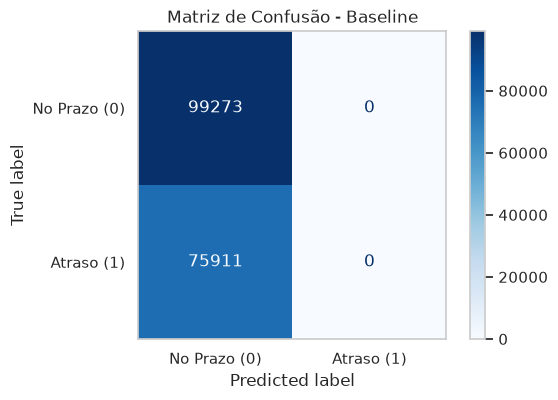

In [5]:
# Fazendo as predições nos dados que o modelo não conhece (teste)
y_pred = baseline_model.predict(X_teste)

# Calculando métricas
acuracia = accuracy_score(y_teste, y_pred)
print(f"Acurácia da Baseline: {acuracia:.4f} ({acuracia * 100:.2f}%)\n")

print("Relatório de Classificação:")
print(classification_report(y_teste, y_pred, zero_division=0))

# Plotando a Matriz de Confusão visualmente
cm = confusion_matrix(y_teste, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Prazo (0)", "Atraso (1)"])

fig, ax = plt.subplots(figsize=(6, 4))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Matriz de Confusão - Baseline")
plt.grid(False)
plt.show()